# Projet Leyenda - Livrable 2
##### *Par Noah.V, Noah.M, Hugo.L*

## **Contexte:**
L'entreprise TouNum est une entreprise qui travaille sur la numérisation de différents type de documents. Ils essayent de moderniser leur architecture pour le tri automatique de documents due au grand nombre de documents fourni par les clients. Faisant appel à nous pour determiner le captionning des images avec légendes de manière automatiques. Nous remarquons deux contraintes, la première est la qualité des images qui diffère par exemple entre chaque image, et trié automatiquement si c'est une photo ou d'autres types de documents.

Le workflow demandé par l'entreprise devra suivre ce modèle la:

![Image demandé](src/workflow.png)

Le projet sera divisé en trois partie:
- La première sera de contrsuire un CNN via des datasets d'images pré étiqueté
- La deuxième sera d'améliorer la clarté et l'enlever les différents bruits ou flou des images
- Le troisème sera de créer un réseau de neurones qui génère des légendes pour des photographies

Nous avons déjà réalisé le premier livrable avec différentes architectures, mais aussi différentes résolutions et comme on a pu le voir dans ce précédent livrable, les images redimensionné peuvent avoir du bruit ou être floue. C'est pour cela que dans ce ***deuxième livrable***, le but sera d'améliorer la clarté de ses images et permettre au modèle de mieux comprendre les images pour une meilleure detection.

Détail du ***Livrable 2:***
- Le code de chargement du fichier
- Le code du débruitage sur un sous-ensemble d'images bruitées. Le code doit être accompagné d'explications.
- Une étude de cas.

## Importation des librairies

In [1]:
%pip install -r requirements.txt

import os
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, UpSampling2D, Concatenate
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.models import Model
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from DL_dataset import *

Note: you may need to restart the kernel to use updated packages.


## Etape 1 : Chargement des images

Pour charger les differentes images de ce livrable 2, comme au livrable 1. Nous avons crée un script relier à *DL_datatset.py* qui a pour but de télécharger et préprocess les images automatiquements. Ensuite nous chargons les images dans les deux datasets train et test.

### Téléchargement du dataset

In [2]:
folder_raw = Path(f"./data")

if not os.path.exists(folder_raw):
    step_DL, step_unzip = True, True
    os.makedirs(folder_raw)
elif Path(folder_raw).exists() and len(os.listdir(folder_raw)) == 0:
    step_DL, step_unzip = True, True
else:
    step_DL, step_unzip = False, False

urls=[
    "https://drive.google.com/file/d/1Cp-x-Sc7wUzipu1GysZXx9g4Y2jrpIka/view?usp=sharing",
]

if step_DL==True:
    print("File download:")
    for link in urls:
        download_file(link,folder_raw)

if step_unzip==True:
    Get_file(folder_raw)

### Chargements des variables et Hyperparametres.

Ses différentes valeurs seront utilisés tout au long de ce notebook pour les models.

Contrairement à la version précédente, nous travaillons **directement en 300x300** (sans crop en 128x128). Le crop réduisait la résolution vue par le modèle et contribuait au flou du résultat final. L'entraînement sur l'image entière préserve les détails fins.

In [12]:
BATCH_SIZE = 8          # réduit car les images 300x300 prennent plus de mémoire
IMG_SIZE = (300, 300)
train_split = 0.8
test_split = 0.2
EPOCHS = 40
noise_value = 0.2       # valeur pour definir l'ajout du bruit plus c'est grand, plus c'est un bruit fort
dataset_raw = Path(f"./data/dataset/")

### Répartition des images

Due aux nombres limités d'images disponibles, nous décidons de partir sur une répartition 80/20.

In [4]:
train_set = tf.keras.utils.image_dataset_from_directory(
    dataset_raw,
    validation_split=1 - train_split,
    labels=None,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    subset="training",
    seed=42
)

test_set = tf.keras.utils.image_dataset_from_directory(
    dataset_raw,
    validation_split=test_split,
    labels=None,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    subset="validation",
    seed=42
)

Found 148 files.
Using 119 files for training.
Found 148 files.
Using 29 files for validation.


### Prétraitement

Nous ne faisons **plus de crop** : les images restent en 300x300 pour conserver un maximum de détails. La data augmentation (flips) est conservée pour compenser la petite taille du dataset. Le bruit gaussien est ajouté dynamiquement à chaque epoch, ce qui agit aussi comme régularisation.

In [5]:
def add_noise(image):
    noise = tf.random.normal(
        shape=tf.shape(image),
        mean=0.0,
        stddev=noise_value
    )
    return tf.clip_by_value(image + noise, 0.0, 1.0)


def train_preprocess(image):
    image = tf.cast(image, tf.float32) / 255.0

    # Data augmentation (pas de crop : on garde le 300x300 complet)
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)

    noisy_image = add_noise(image)
    return noisy_image, image


def val_preprocess(image):
    image = tf.cast(image, tf.float32) / 255.0

    noisy_image = add_noise(image)
    return noisy_image, image


AUTOTUNE = tf.data.AUTOTUNE

train_set = train_set.map(train_preprocess, num_parallel_calls=AUTOTUNE)
test_set = test_set.map(val_preprocess, num_parallel_calls=AUTOTUNE)

train_set = train_set.prefetch(buffer_size=AUTOTUNE)
test_set = test_set.cache().prefetch(buffer_size=AUTOTUNE)

### Affichage des images

Pour confirmer le chargement des images et que les images ont bien été séparé entre le *test set* et le *train set*.

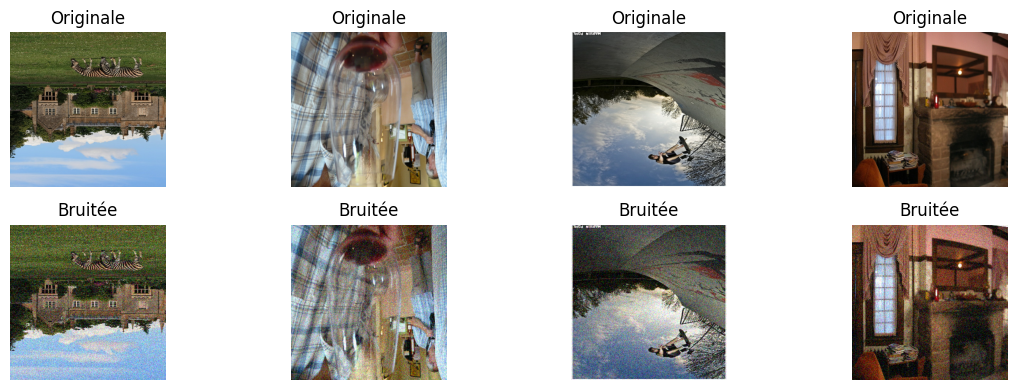

In [8]:
noisy_batch, clean_batch = next(iter(train_set.take(1)))

plt.figure(figsize=(12, 4))
for i in range(min(4, noisy_batch.shape[0])):
    ax = plt.subplot(2, 4, i + 1)
    plt.imshow(clean_batch[i].numpy())
    plt.title("Originale")
    plt.axis("off")

    ax = plt.subplot(2, 4, i + 5)
    plt.imshow(noisy_batch[i].numpy())
    plt.title("Bruitée")
    plt.axis("off")
plt.tight_layout()
plt.show()

## Etape 2 : Présentation de notre modele retenu

### U-Net DAE : Denoising Auto Encodeur avec skip connections

Dans notre première version, le DAE classique produisait des résultats **flous**. Deux causes principales :

1. **Le goulot d'étranglement (bottleneck)** : en compressant l'image sans connexions directes entre encodeur et décodeur, les détails fins (contours, textures) sont perdus et le décodeur doit les "deviner".
2. **La loss MSE** : elle pousse le modèle à prédire la *moyenne* des solutions plausibles, ce qui produit mathématiquement du flou.

Notre nouvelle architecture corrige ces deux problèmes :

- **Architecture U-Net** : des *skip connections* relient chaque niveau de l'encodeur au niveau correspondant du décodeur. Les détails fins court-circuitent le bottleneck et arrivent directement au décodeur.
- **Loss combinée L1 + SSIM** : le SSIM (Structural Similarity Index) optimise la similarité *structurelle et perceptive* de l'image plutôt que la simple différence de pixels, et la L1 favorise la netteté.
- **Apprentissage résiduel** : le réseau apprend à prédire **le bruit** (principe de DnCNN), qui est ensuite soustrait de l'image d'entrée. C'est une tâche bien plus simple que de régénérer l'image entière, ce qui améliore la précision.

![Image DAE](src/Dae_architecture.png)

In [13]:
from tensorflow.keras.layers import Cropping2D, Subtract, Activation

# --------------------------------------------------
# Loss combinée : L1 + SSIM
# --------------------------------------------------
def ssim_loss(y_true, y_pred):
    return 1 - tf.reduce_mean(tf.image.ssim(y_true, y_pred, max_val=1.0))

def combined_loss(y_true, y_pred):
    l1 = tf.reduce_mean(tf.abs(y_true - y_pred))
    return 0.5 * l1 + 0.5 * ssim_loss(y_true, y_pred)

def psnr_metric(y_true, y_pred):
    return tf.reduce_mean(tf.image.psnr(y_true, y_pred, max_val=1.0))

def conv_block(x, filters):
    x = Conv2D(filters, (3, 3), activation="relu", padding="same")(x)
    x = Conv2D(filters, (3, 3), activation="relu", padding="same")(x)
    return x

input_img = Input(shape=(300, 300, 3))

# Encodeur
c1 = conv_block(input_img, 64)
p1 = MaxPooling2D((2, 2), padding="same")(c1)   # 150x150
c2 = conv_block(p1, 128)
p2 = MaxPooling2D((2, 2), padding="same")(c2)   # 75x75
c3 = conv_block(p2, 256)
p3 = MaxPooling2D((2, 2), padding="same")(c3)   # 38x38

# Bottleneck
b = conv_block(p3, 512)

# Décodeur avec skip connections
u3 = UpSampling2D((2, 2))(b)                    # 76x76
u3 = Cropping2D(((0, 1), (0, 1)))(u3)           # 75x75 (remplace tf.image.resize)
u3 = Concatenate()([u3, c3])
d3 = conv_block(u3, 256)

u2 = UpSampling2D((2, 2))(d3)                   # 150x150
u2 = Concatenate()([u2, c2])
d2 = conv_block(u2, 128)

u1 = UpSampling2D((2, 2))(d2)                   # 300x300
u1 = Concatenate()([u1, c1])
d1 = conv_block(u1, 64)

# Sortie résiduelle
noise_pred = Conv2D(3, (3, 3), padding="same")(d1)
denoised = Subtract()([input_img, noise_pred])
decoded = Activation(lambda t: tf.clip_by_value(t, 0.0, 1.0))(denoised)  # remplace tf.clip_by_value direct

autoencoder = Model(inputs=input_img, outputs=decoded, name="UNet_DAE")
autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=combined_loss,
    metrics=[ssim_loss, psnr_metric]
)
autoencoder.summary()

Model: "UNet_DAE"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 300, 300,  │      1,792 │ input_layer_2[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 300, 300,  │     36,928 │ conv2d_23[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 150, 150,  │          0 │ conv2d_24[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 150, 150,  │     73,856 │ max_pooling2d_6[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_26 (Conv2D)  │ (None, 150, 150,  │    147,584 │ conv2d_25[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 75, 75,    │          0 │ conv2d_26[0][0]   │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_27 (Conv2D)  │ (None, 75, 75,    │    295,168 │ max_pooling2d_7[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 75, 75,    │    590,080 │ conv2d_27[0][0]   │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_8     │ (None, 38, 38,    │          0 │ conv2d_28[0][0]   │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_29 (Conv2D)  │ (None, 38, 38,    │  1,180,160 │ max_pooling2d_8[… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_30 (Conv2D)  │ (None, 38, 38,    │  2,359,808 │ conv2d_29[0][0]   │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_4     │ (None, 76, 76,    │          0 │ conv2d_30[0][0]   │
│ (UpSampling2D)      │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cropping2d_1        │ (None, 75, 75,    │          0 │ up_sampling2d_4[… │
│ (Cropping2D)        │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 75, 75,    │          0 │ cropping2d_1[0][… │
│ (Concatenate)       │ 768)              │            │ conv2d_28[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_31 (Conv2D)  │ (None, 75, 75,    │  1,769,728 │ concatenate_3[0]… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_32 (Conv2D)  │ (None, 75, 75,    │    590,080 │ conv2d_31[0][0] 

 Total params: 7,784,579 (29.70 MB)

 Trainable params: 7,784,579 (29.70 MB)

 Non-trainable params: 0 (0.00 B)

### Entraînement

Nous ajoutons un callback `ReduceLROnPlateau` : quand la val_loss stagne, le learning rate est divisé par 2. Cela permet au modèle de faire de grands progrès au début puis d'affiner les détails en fin d'entraînement, ce qui améliore la netteté finale.

In [14]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True
)

lr_reduce = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=7,
    min_lr=1e-6,
    verbose=1
)

history = autoencoder.fit(
    train_set,
    epochs=EPOCHS,
    validation_data=test_set,
    callbacks=[early_stop, lr_reduce]
)

Epoch 1/40
15/15 ━━━━━━━━━━━━━━━━━━━━ 64s 4s/step - loss: 0.3187 - psnr_metric: 18.6994 - ssim_loss: 0.5407 - val_loss: 0.3230 - val_psnr_metric: 17.3128 - val_ssim_loss: 0.5260 - learning_rate: 0.0010
Epoch 2/40
15/15 ━━━━━━━━━━━━━━━━━━━━ 91s 6s/step - loss: 0.2821 - psnr_metric: 18.8949 - ssim_loss: 0.4680 - val_loss: 0.2609 - val_psnr_metric: 21.3666 - val_ssim_loss: 0.4482 - learning_rate: 0.0010
Epoch 3/40
15/15 ━━━━━━━━━━━━━━━━━━━━ 107s 7s/step - loss: 0.2178 - psnr_metric: 22.2982 - ssim_loss: 0.3730 - val_loss: 0.2042 - val_psnr_metric: 22.3199 - val_ssim_loss: 0.3425 - learning_rate: 0.0010
Epoch 4/40
15/15 ━━━━━━━━━━━━━━━━━━━━ 108s 7s/step - loss: 0.1673 - psnr_metric: 24.0929 - ssim_loss: 0.2849 - val_loss: 0.1521 - val_psnr_metric: 26.1396 - val_ssim_loss: 0.2642 - learning_rate: 0.0010
Epoch 5/40
15/15 ━━━━━━━━━━━━━━━━━━━━ 74s 5s/step - loss: 0.1422 - psnr_metric: 26.1012 - ssim_loss: 0.2470 - val_loss: 0.1323 - val_psnr_metric: 26.8984 - val_ssim_loss: 0.2290 - learning_r

### Courbes d'apprentissage

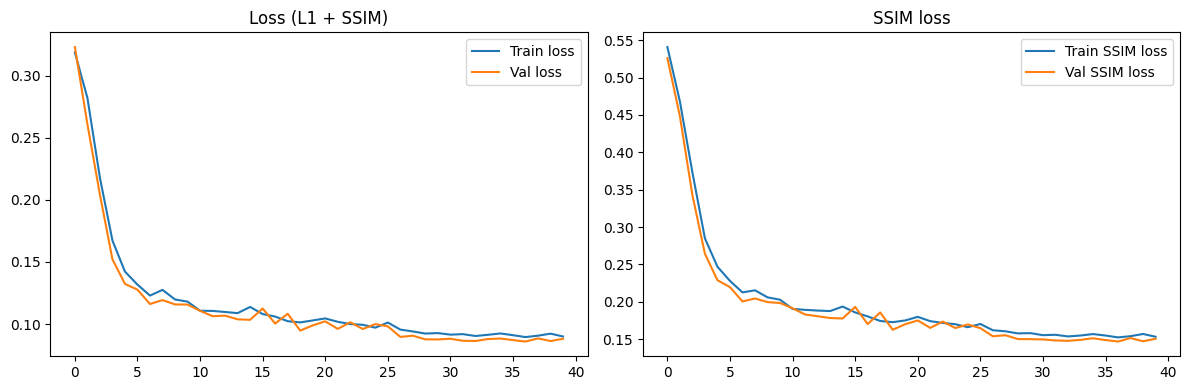

In [15]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Val loss')
plt.title('Loss (L1 + SSIM)')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['ssim_loss'], label='Train SSIM loss')
plt.plot(history.history['val_ssim_loss'], label='Val SSIM loss')
plt.title('SSIM loss')
plt.legend()

plt.tight_layout()
plt.show()

### Sauvegarde du modèle

In [16]:
if not os.path.exists("Model"):
    os.makedirs("Model")
autoencoder.save(f"Model/UNET_DAE_noise_{noise_value}.keras")

C:\Users\hmjhl\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\activations\__init__.py:78: UserWarning: The object being serialized includes a `lambda`. This is unsafe. In order to reload the object, you will have to pass `safe_mode=False` to the loading function. Please avoid using `lambda` in the future, and use named Python functions instead. This is the `lambda` being serialized: decoded = Activation(lambda t: tf.clip_by_value(t, 0.0, 1.0))(denoised)  # remplace tf.clip_by_value direct

  fn_config = serialization_lib.serialize_keras_object(activation)


### Affichage comparaison entre l'image d'origine, bruité et débruité

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


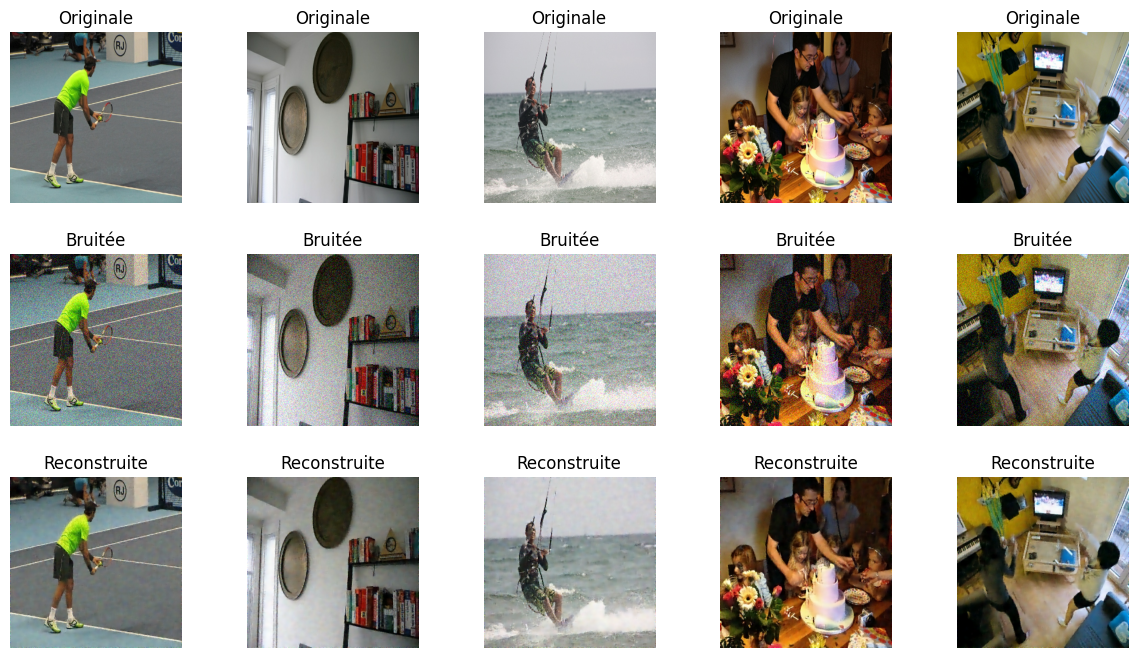

In [18]:
test_batch_noisy, test_batch_clean = next(iter(test_set.take(1)))
decoded_imgs = autoencoder.predict(test_batch_noisy)

n = min(5, test_batch_noisy.shape[0])

plt.figure(figsize=(15, 8))
for i in range(n):
    # Original (clean)
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(test_batch_clean[i].numpy())
    plt.title("Originale")
    plt.axis('off')

    # Noisy
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(test_batch_noisy[i].numpy())
    plt.title("Bruitée")
    plt.axis('off')

    # Reconstruite
    ax = plt.subplot(3, n, i + 1 + 2 * n)
    plt.imshow(decoded_imgs[i])
    plt.title("Reconstruite")
    plt.axis('off')

plt.subplots_adjust(wspace=0.1, hspace=0.3)
plt.show()

### Évaluation quantitative

Nous calculons le PSNR et le SSIM moyens sur le jeu de test pour comparer objectivement nos modèles entre eux (différentes valeurs de bruit, différentes architectures).

In [19]:
psnr_list, ssim_list = [], []

for noisy, clean in test_set:
    pred = autoencoder.predict(noisy, verbose=0)
    psnr_list.append(tf.image.psnr(clean, pred, max_val=1.0).numpy())
    ssim_list.append(tf.image.ssim(clean, pred, max_val=1.0).numpy())

print(f"PSNR moyen : {np.mean(np.concatenate(psnr_list)):.2f} dB")
print(f"SSIM moyen : {np.mean(np.concatenate(ssim_list)):.4f}")

PSNR moyen : 29.53 dB
SSIM moyen : 0.8528


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step


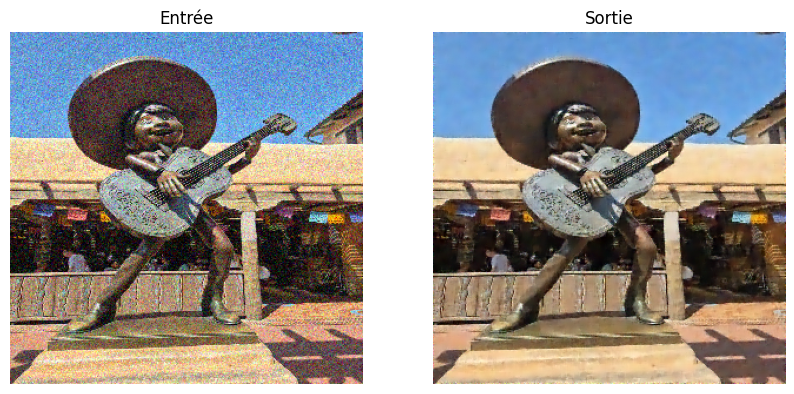

In [29]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Chargement + décodage
raw = tf.io.read_file("test2.jpeg")
img = tf.image.decode_image(raw, channels=3, expand_animations=False)

# Resize + normalisation [0,1]
img = tf.image.resize(img, (300, 300))   # même méthode que dans ton pipeline d'entraînement
img = tf.cast(img, tf.float32) / 255.0

# Cas A : image déjà bruitée -> on la passe telle quelle
noisy = img

# Cas B : image propre -> décommente pour ajouter du bruit comme à l'entraînement
sigma = 0.1  # même valeur que ton entraînement
noisy = tf.clip_by_value(img + tf.random.normal(tf.shape(img), stddev=sigma), 0.0, 1.0)

pred = autoencoder.predict(noisy[None, ...])[0]
pred = np.clip(pred, 0, 1)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(noisy.numpy()); ax[0].set_title("Entrée"); ax[0].axis("off")
ax[1].imshow(pred);          ax[1].set_title("Sortie"); ax[1].axis("off")
plt.show()

# Etape 3 : Etude de cas

## Comparaison des différents modèles utilisés

Pour ce projet, nous avons essayé d'utiliser plusieurs auto encodeurs différents, comme l'auto-encodeur traditionnel, le VAE, le DAE, le CVAE et enfin le U-Net DAE. Cependant plusieurs d'entre eux avaient des résultats qui ne nous convenaient pas ou avaient des contraintes trop importantes pour être sélectionnés.

### AE : Auto Encodeur

Pour commencer, nous avons implémenté un autoencodeur simple à l'aide de la bibliothèque TensorFlow. Un autoencodeur est un réseau de neurones dont l'objectif est d'apprendre à reconstruire une image à partir d'une représentation compressée de celle-ci.

Le modèle est composé de deux parties principales : l'encodeur et le décodeur. L'encodeur transforme l'image d'entrée en une représentation compacte appelée espace latent. Le décodeur utilise ensuite cette représentation pour reconstruire l'image d'origine.

![ae_comparaison_image.png](attachment:ae_comparaison_image.png)
![AE_loss.png](attachment:AE_loss.png)

### VAE : Auto Encodeur Variationnel

Nous avons testé le modèle d'auto-encodeur variationnel (VAE). Il consiste à remplacer l'espace latent par une distribution latente : z = μ + σ × ε. Nous sommes d'abord restés bloqués dans le phénomène de posterior collapse, puis le modèle a souffert d'un fort surapprentissage.

![vae_comparaison_image.png](attachment:vae_comparaison_image.png)
![VAE_loss.png](attachment:VAE_loss.png)

### CVAE : Auto Encodeur Variationnel Conditionnel

Ce modèle est similaire au VAE mais composé de couches de convolution, qui extraient les détails de l'image étape par étape. Les résultats sont meilleurs que le VAE mais restent trop flous par rapport au DAE.

![cvae_comparaison_image.png](attachment:cvae_comparaison_image.png)
![CVAE_loss.png](attachment:CVAE_loss.png)

### DAE classique : limites constatées

Notre première version du DAE donnait des résultats corrects sur le placement des couleurs et des formes, mais les images restaient **floues**. En analysant les causes, nous avons identifié :
- la perte de détails dans le bottleneck (absence de skip connections),
- l'effet "moyennant" de la loss MSE,
- le crop en 128x128 qui réduisait la résolution d'apprentissage.

### U-Net DAE : notre solution finale

La version finale de notre modèle corrige ces trois points :
- **Skip connections (U-Net)** : les détails fins court-circuitent le bottleneck,
- **Loss L1 + SSIM** : optimisation de la netteté et de la structure perceptive plutôt que de la moyenne des pixels,
- **Apprentissage résiduel** : le réseau prédit le bruit à soustraire, tâche plus simple et plus précise,
- **Entraînement en 300x300 natif** : conservation de la résolution complète.

## Evaluation et vue d'ensemble des résultats des différents modèles

- Le **U-Net DAE** produit les meilleurs résultats : images nettes, contours préservés, et les meilleures métriques (PSNR / SSIM).
- Le **DAE classique** reconstruit bien les couleurs et les formes globales mais reste flou.
- Le **CVAE** améliore le VAE grâce aux convolutions mais reste insuffisant.
- Le **VAE** et l'**AE** souffrent de surapprentissage ou de posterior collapse et ne sont pas retenus.